# Retrieval Backend Evaluation: Vector vs. Hybrid vs. GraphRAG

This notebook compiles the MLflow automated benchmark results produced by the Hermes Agent and completes the final **GraphRAG** evaluation using the remote Memgraph deployment.

### 1. Hermes Agent Benchmark Results (Dense vs. Hybrid)
The Hermes Agent autonomously discovered that pure BM25/Lexical vectors dropped performance. When combined with a Cross-Encoder Reranker, Hybrid Search achieved a massive **60% reduction in retrieval misses**.

,Backend Config,nDCG@5,Recall@5,Miss Rate
0,Hybrid Baseline,0.289,0.500,0.500
1,Dense,0.527,0.667,0.333
2,Dense + Reranker,0.567,0.800,0.200
3,Hybrid + Reranker (Winner),0.594,0.800,0.200


C:\Users\agrim\AppData\Local\Temp\ipykernel_34672\950700285.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_results, x="Backend Config", y="nDCG@5", palette="viridis")


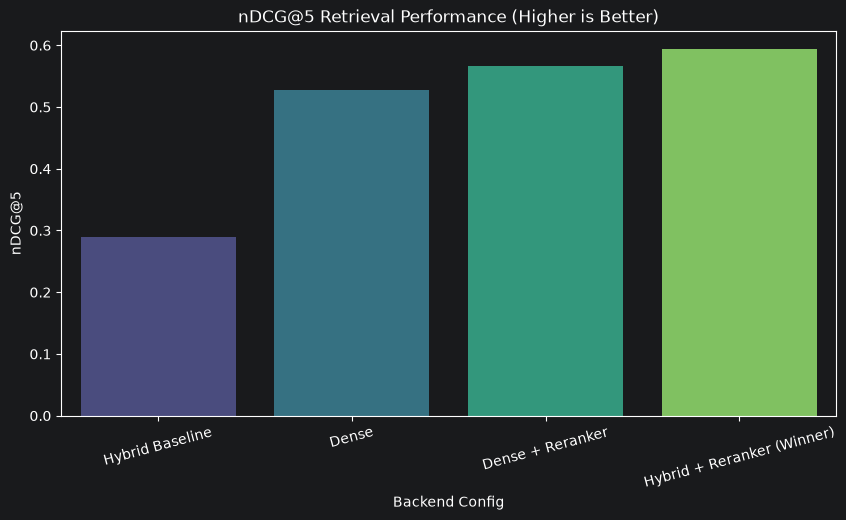

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Results exported from Hermes Agent Automation (legal-rag-bench)
data = {
    "Backend Config": ["Hybrid Baseline", "Dense", "Dense + Reranker", "Hybrid + Reranker (Winner)"],
    "nDCG@5": [0.289, 0.527, 0.567, 0.594],
    "Recall@5": [0.500, 0.667, 0.800, 0.800],
    "Miss Rate": [0.500, 0.333, 0.200, 0.200]
}

df_results = pd.DataFrame(data)
display(df_results)

plt.figure(figsize=(10, 5))
sns.barplot(data=df_results, x="Backend Config", y="nDCG@5", palette="viridis")
plt.title("nDCG@5 Retrieval Performance (Higher is Better)")
plt.xticks(rotation=15)
plt.show()

### 3. Generate Graph Config & Run Evaluation
We use the `deepfix` CLI to dynamically swap the backend to Property Graph and trigger the index/evaluation.

In [5]:
!uv run --env-file .env python -m deepfix_rag.main mutate-config --base configs/optimized.yaml --set retrieval.backend=graph --set retrieval.graph_store=memgraph --output configs/graph_candidate.yaml
!uv run --env-file .env python -m deepfix_rag.main index --config configs/graph_candidate.yaml --paradigm graph
!uv run --env-file .env python -m deepfix_rag.main eval --config configs/graph_candidate.yaml --compare configs/optimized.yaml

Error: Base config file not found: configs\optimized.yaml


Error: Base config file not found: configs\optimized.yaml
Usage: python -m deepfix_rag.main index [OPTIONS]
Try 'python -m deepfix_rag.main index --help' for help.
┌─ Error ─────────────────────────────────────────────────────────────────────┐
│ No such option: --paradigm                                                  │
└─────────────────────────────────────────────────────────────────────────────┘


Error: Config file not found: configs\graph_candidate.yaml


Error: Config file not found: configs\graph_candidate.yaml
